# Comparativa de Kernels de Proyección: Frobenius, Random Walk y Shortest Path
Este notebook evalúa y compara el comportamiento de tres familias de kernels de proyección distintas en el Hashing Sensible a la Localidad (LSH-HLA) para agrupar grafos sintéticos con perturbaciones de aristas (ruido):
1. **Frobenius Inner Product:** Mapeo lineal de solapamiento exacto de aristas.
2. **Random Walk Graph Kernel:** Mapeo de similitud basado en estadísticas de caminos de longitud $p$.
3. **Shortest Path Graph Kernel:** Mapeo de similitud topológica basado en matrices de caminos más cortos.

Se genera un dataset sintético con 1,000 grafos en total (500 de tipo Estrella y 500 de tipo Ciclo) con un nodo raíz 0 y orden secuencial alineados, a los cuales se les aplica ruido (eliminando y añadiendo 1 arista). Se evalúan los tiempos de ejecución y la F1-score resultante al cortar el dendrograma en 2 clusters, comparando contra el Baseline jerárquico.


In [1]:
import numpy as np
import networkx as nx
from scipy.linalg import eig
from heapq import heappush, heappop
from collections import defaultdict
from tqdm import tqdm
import pandas as pd
import matplotlib.pyplot as plt
import time
import random
from sklearn.metrics import precision_recall_fscore_support, classification_report

# ----------------------------------------------------
# 1. Definición de los 3 Kernels de Proyección en LSH
# ----------------------------------------------------

def projection_frobenius(A, B):
    # Producto interno de Frobenius literal (traza de A.T @ B)
    return np.trace(np.dot(A.T, B))


def projection_random_walk(A, B):
    # Kernel de caminatas aleatorias de p-pasos (p=3, beta=0.05)
    p = 3
    beta = 0.05
    N = A.shape[0]
    
    val = float(N)
    A_k = np.eye(N)
    B_k = np.eye(N)
    
    for k in range(1, p + 1):
        A_k = np.dot(A_k, A)
        B_k = np.dot(B_k, B)
        val += (beta ** k) * np.sum(A_k) * np.sum(B_k)
        
    return val


def projection_shortest_path(A, B):
    # Kernel de caminos más cortos (Shortest Path Graph Kernel, unweighted)
    from scipy.sparse.csgraph import shortest_path
    
    DA = shortest_path(A, directed=False, unweighted=True)
    DB = shortest_path(B, directed=False, unweighted=True)
    
    DA[np.isinf(DA)] = 99.0
    DB[np.isinf(DB)] = 99.0
    
    gamma = 0.5
    val = np.sum(np.exp(-gamma * np.abs(DA - DB)))
    return float(val)

# Alias para compatibilidad hacia atrás
matrix_prod_trace = projection_shortest_path

# ----------------------------------------------------
# 2. Funciones Base de Clustering Ponderado (Suma Directa)
# ----------------------------------------------------

def get_graph(edges, nodes):
    g = nx.Graph()
    g.add_edges_from(edges)
    g.add_nodes_from(nodes)
    return g


def hash_p_stable(projection, r):
    if r <= 0:
        return 0
    b = np.random.uniform(0, r)
    return int(np.floor((projection + b) / r))


def get_erdos_renyi_graph(n, p):
    while True:
        g = nx.erdos_renyi_graph(n, p)
        if g.number_of_edges() > 0:
            return g


def get_adjacency(g, N):
    if 'adjacency' in g.graph:
        return g.graph['adjacency']

    g_copy = g.copy()
    g_copy.remove_edges_from(nx.selfloop_edges(g_copy))

    nodes_order = list(sorted(g_copy.nodes()))

    A = nx.adjacency_matrix(
        g_copy,
        nodelist=nodes_order,
        weight='weight'
    ).toarray().astype(float)

    M = A.shape[0]
    A = np.pad(A, [(0, N - M), (0, N - M)], mode="constant")

    if not g.graph.get('is_merged', False):
        A = (A > 0).astype(float)

    np.fill_diagonal(A, 0)
    g.graph['adjacency'] = A
    return A


def get_density_matrix(A):
    num_edges = np.sum(A) / 2.0
    if num_edges == 0:
        return np.zeros_like(A)
    degrees = np.sum(A, axis=1)
    L = np.diag(degrees) - A
    return L / (2.0 * num_edges)


def entropy_from_rho(rho):
    eigvals = np.linalg.eigvalsh(rho)
    eigvals[eigvals < 1e-12] = 0.0
    eigvals = eigvals[eigvals > 1e-12]
    return float(-np.sum(eigvals * np.log2(eigvals)))


def von_newmann_entropy(g):
    if 'vn_entropy' in g.graph:
        return g.graph['vn_entropy']

    A = get_adjacency(g, 10)
    rho = get_density_matrix(A)
    entropy = entropy_from_rho(rho)
    
    g.graph['vn_entropy'] = entropy
    g.graph['rho'] = rho
    return entropy


def get_rho(g, N):
    if 'rho' in g.graph:
        return g.graph['rho']
    A = get_adjacency(g, N)
    rho = get_density_matrix(A)
    g.graph['rho'] = rho
    return rho


def aggregate(g1, g2, N):
    A1 = get_adjacency(g1, N)
    A2 = get_adjacency(g2, N)

    A = A1 + A2
    np.fill_diagonal(A, 0)
    
    g = nx.from_numpy_array(A)
    g.graph['is_merged'] = True
    return g


def js_divergence(g1, g2, N):
    rho1 = get_rho(g1, N)
    rho2 = get_rho(g2, N)

    # Mezcla 50/50 de las matrices de densidad
    rho_mix = (rho1 + rho2) / 2.0

    h_mix = entropy_from_rho(rho_mix)
    h_avg = (von_newmann_entropy(g1) + von_newmann_entropy(g2)) / 2.0
    val = max(h_mix - h_avg, 0.0)
    return np.sqrt(val)


def get_bucket_id_for_graph(g, random_graphs, B, projection_ranges, N_pad, proj_func):
    bucket_id = ""
    A = get_adjacency(g, N_pad)

    for k, erg in enumerate(random_graphs):
        A_er = get_adjacency(erg, N_pad)
        proj = proj_func(A, A_er)

        min_proj, max_proj = projection_ranges[k]
        r = (max_proj - min_proj) / B

        hash_bin = hash_p_stable(proj, r)
        bucket_id += f"{hash_bin}_"

    return bucket_id


def aggregate_many(graph_list, N):
    A_union = np.zeros((N, N))
    for g in graph_list:
        A_union += get_adjacency(g, N)

    np.fill_diagonal(A_union, 0)

    g = nx.from_numpy_array(A_union)
    g.graph['is_merged'] = True
    return g


def quality(active, clusters, h_total=None, N_pad=None):
    active = list(active)
    if len(active) == 0:
        return 0.0

    if N_pad is None:
        N_pad = max(g.number_of_nodes() for g in clusters.values())

    active_graphs = [clusters[i] for i in active]

    if h_total is None:
        active_rhos = [get_rho(g, N_pad) for g in active_graphs]
        rho_total = np.mean(active_rhos, axis=0)
        h_total = entropy_from_rho(rho_total)

    if h_total <= 1e-12:
        return 0.0

    H_C = np.mean([
        von_newmann_entropy(g)
        for g in active_graphs
    ])

    q = 1.0 - (H_C / h_total)
    return float(q)


def refill_heap_global(active, clusters, N_pad):
    heap = []
    active_list = list(active)

    for a in range(len(active_list)):
        for b in range(a + 1, len(active_list)):
            i = active_list[a]
            j = active_list[b]

            dist = js_divergence(clusters[i], clusters[j], N_pad)
            heappush(heap, (dist, i, j))

    return heap


def has_bucket_candidates(bucket_members, active):
    for members in bucket_members.values():
        alive = [x for x in members if x in active]
        if len(alive) >= 2:
            return True
    return False

# -------------------------
# Funciones controladoras (LSH y Baseline con Mezcla de Rho)
# -------------------------

def build_lsh_buckets(graphs, num_proj, B, proj_func, p_er=0.8):
    num_graphs = len(graphs)
    N_pad = max(g.number_of_nodes() for g in graphs)

    bucket_ids = [""] * num_graphs
    random_graphs = []
    projection_ranges = []

    for k in tqdm(range(num_proj), desc="LSH projections", leave=False):
        erg = get_erdos_renyi_graph(N_pad, p_er)
        random_graphs.append(erg)
        A_er = get_adjacency(erg, N_pad)

        projections = []
        for g in graphs:
            A = get_adjacency(g, N_pad)
            proj = proj_func(A, A_er)
            projections.append(proj)

        min_proj = min(projections)
        max_proj = max(projections)
        projection_ranges.append((min_proj, max_proj))

        r = (max_proj - min_proj) / B
        for i in range(num_graphs):
            hash_bin = hash_p_stable(projections[i], r)
            bucket_ids[i] += f"{hash_bin}_"

    buckets = defaultdict(list)
    for i, bid in enumerate(bucket_ids):
        buckets[bid].append(i)

    return buckets, bucket_ids, random_graphs, projection_ranges


def hierarchical_bucket_heap_dynamic(
    graphs,
    buckets,
    bucket_ids,
    random_graphs,
    projection_ranges,
    B,
    proj_func,
    epsilon=np.inf
):
    num_graphs = len(graphs)
    N_pad = max(g.number_of_nodes() for g in graphs)

    active = set(range(num_graphs))
    clusters = {i: graphs[i] for i in range(num_graphs)}
    cluster_bucket = {i: bucket_ids[i] for i in range(num_graphs)}

    bucket_members = defaultdict(set)
    for bid, indices in buckets.items():
        bucket_members[bid].update(indices)

    # h_total basado en promedio de matrices de densidad de todos los grafos activos
    active_rhos = [get_rho(clusters[i], N_pad) for i in active]
    rho_total = np.mean(active_rhos, axis=0)
    h_total = entropy_from_rho(rho_total)
    
    heap = []
    for bid, members in bucket_members.items():
        members = list(members)
        for a in range(len(members)):
            for b in range(a + 1, len(members)):
                i = members[a]
                j = members[b]
                dist = js_divergence(clusters[i], clusters[j], N_pad)
                heappush(heap, (dist, i, j))

    Z = []
    next_cluster_id = num_graphs
    global_mode = False

    while len(active) > 1:
        if not global_mode and not has_bucket_candidates(bucket_members, active):
            global_mode = True
            heap = refill_heap_global(active, clusters, N_pad)

        if len(heap) == 0:
            if global_mode:
                heap = refill_heap_global(active, clusters, N_pad)
            else:
                break

        dist, i, j = heappop(heap)
        if i not in active or j not in active:
            continue

        if not global_mode and cluster_bucket[i] != cluster_bucket[j]:
            continue

        if dist > epsilon:
            break

        same_bucket = cluster_bucket[i] == cluster_bucket[j]
        old_bucket_i = cluster_bucket[i]
        old_bucket_j = cluster_bucket[j]

        new_id = next_cluster_id
        next_cluster_id += 1

        new_graph = aggregate(clusters[i], clusters[j], N_pad)

        active.remove(i)
        active.remove(j)
        bucket_members[old_bucket_i].discard(i)
        bucket_members[old_bucket_j].discard(j)

        clusters[new_id] = new_graph
        active.add(new_id)

        new_bucket_id = get_bucket_id_for_graph(
            new_graph,
            random_graphs=random_graphs,
            B=B,
            projection_ranges=projection_ranges,
            N_pad=N_pad,
            proj_func=proj_func
        )
        cluster_bucket[new_id] = new_bucket_id
        bucket_members[new_bucket_id].add(new_id)

        # Recalcular h_total
        active_rhos = [get_rho(clusters[x], N_pad) for x in active]
        rho_total = np.mean(active_rhos, axis=0)
        h_total = entropy_from_rho(rho_total)

        q = quality(active=active, clusters=clusters, h_total=h_total, N_pad=N_pad)
        Z.append([i, j, dist, q, new_id, new_bucket_id, same_bucket, global_mode])

        if global_mode:
            for other in list(active):
                if other == new_id:
                    continue
                new_dist = js_divergence(clusters[new_id], clusters[other], N_pad)
                heappush(heap, (new_dist, new_id, other))
        else:
            for other in list(bucket_members[new_bucket_id]):
                if other == new_id or other not in active:
                    continue
                new_dist = js_divergence(clusters[new_id], clusters[other], N_pad)
                heappush(heap, (new_dist, new_id, other))

    return Z, clusters, active, bucket_members


def shclust_heap_dynamic(graphs, num_proj=3, B=10, proj_func=projection_shortest_path, epsilon=np.inf):
    buckets, bucket_ids, random_graphs, projection_ranges = build_lsh_buckets(
        graphs,
        num_proj=num_proj,
        B=B,
        proj_func=proj_func
    )

    Z, clusters, active, bucket_members = hierarchical_bucket_heap_dynamic(
        graphs=graphs,
        buckets=buckets,
        bucket_ids=bucket_ids,
        random_graphs=random_graphs,
        projection_ranges=projection_ranges,
        B=B,
        proj_func=proj_func,
        epsilon=epsilon
    )

    return Z, clusters, active, bucket_members, bucket_ids


def hierarchical_clustering_heap(graphs, epsilon=np.inf):
    num_graphs = len(graphs)
    N_pad = max(g.number_of_nodes() for g in graphs)

    active = set(range(num_graphs))
    clusters = {i: graphs[i] for i in range(num_graphs)}

    active_rhos = [get_rho(clusters[i], N_pad) for i in active]
    rho_total = np.mean(active_rhos, axis=0)
    h_total = entropy_from_rho(rho_total)

    heap = []
    active_list = list(active)
    for a in tqdm(range(len(active_list)), desc="Inicializando heap"):
        for b in range(a + 1, len(active_list)):
            i = active_list[a]
            j = active_list[b]
            dist = js_divergence(clusters[i], clusters[j], N_pad)
            heappush(heap, (dist, i, j))

    Z = []
    next_cluster_id = num_graphs

    while len(active) > 1 and len(heap) > 0:
        dist, i, j = heappop(heap)
        if i not in active or j not in active:
            continue

        if dist > epsilon:
            break

        new_id = next_cluster_id
        next_cluster_id += 1

        new_graph = aggregate(clusters[i], clusters[j], N_pad)
        active.remove(i)
        active.remove(j)

        clusters[new_id] = new_graph
        active.add(new_id)

        # Recalcular h_total
        active_rhos = [get_rho(clusters[x], N_pad) for x in active]
        rho_total = np.mean(active_rhos, axis=0)
        h_total = entropy_from_rho(rho_total)

        q = quality(active=active, clusters=clusters, h_total=h_total, N_pad=N_pad)
        Z.append([i, j, dist, q, new_id])

        for other in list(active):
            if other == new_id:
                continue
            new_dist = js_divergence(clusters[new_id], clusters[other], N_pad)
            heappush(heap, (new_dist, new_id, other))

    return Z, clusters, active


## 1. Generación del Dataset Controlado (1,000 grafos con ruido)


In [2]:
# Configurar semillas para reproducibilidad
np.random.seed(42)
random.seed(42)

graphs = []
true_labels = [] # 0 para Estrella (Star), 1 para Ciclo (Cycle)

# 1. Generar 500 grafos estrella aleatorios de 10 nodos usando nx.star_graph
# Centro es 0, hojas 1..9. Perturbamos ligeramente sin reetiquetar los nodos.
for _ in range(500):
    g = nx.star_graph(9) # Centro es 0, hojas 1..9
    # Remover una arista al azar
    edges = list(g.edges())
    g.remove_edge(*random.choice(edges))
    # Agregar una arista aleatoria inexistente
    while True:
        u, v = random.sample(range(10), 2)
        if not g.has_edge(u, v):
            g.add_edge(u, v)
            break
    graphs.append(g)
    true_labels.append(0)

# 2. Generar 500 grafos ciclo aleatorios de 10 nodos usando nx.cycle_graph
# Ciclo es 0-1-2-...-9-0. Perturbamos ligeramente sin reetiquetar los nodos.
for _ in range(500):
    g = nx.cycle_graph(10) # Ciclo 0-1-2-...-9-0
    # Remover una arista al azar
    edges = list(g.edges())
    g.remove_edge(*random.choice(edges))
    # Agregar una arista aleatoria inexistente
    while True:
        u, v = random.sample(range(10), 2)
        if not g.has_edge(u, v):
            g.add_edge(u, v)
            break
    graphs.append(g)
    true_labels.append(1)

# Mezclar el dataset
indices = list(range(1000))
random.shuffle(indices)

graphs = [graphs[i] for i in indices]
true_labels = np.array([true_labels[i] for i in indices])

print(f"Dataset generado con éxito:")
print(f"Total de grafos: {len(graphs)}")
print(f"Grafos Estrella: {np.sum(true_labels == 0)}")
print(f"Grafos Ciclo: {np.sum(true_labels == 1)}")


Dataset generado con éxito:
Total de grafos: 1000
Grafos Estrella: 500
Grafos Ciclo: 500


### Visualización de los Grafos Sintéticos Perturbados


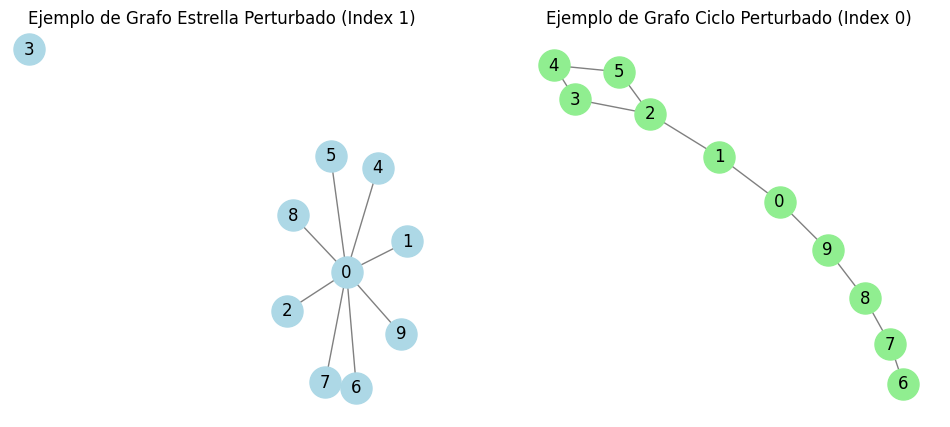

In [3]:
# Graficar un ejemplo de cada tipo de grafo
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Buscar el primer estrella
star_idx = np.where(true_labels == 0)[0][0]
pos_star = nx.spring_layout(graphs[star_idx], seed=42)
nx.draw(graphs[star_idx], pos=pos_star, ax=axes[0], with_labels=True, node_color='lightblue', edge_color='gray', node_size=500)
axes[0].set_title(f"Ejemplo de Grafo Estrella Perturbado (Index {star_idx})")

# Buscar el primer ciclo
cycle_idx = np.where(true_labels == 1)[0][0]
pos_cycle = nx.spring_layout(graphs[cycle_idx], seed=42)
nx.draw(graphs[cycle_idx], pos=pos_cycle, ax=axes[1], with_labels=True, node_color='lightgreen', edge_color='gray', node_size=500)
axes[1].set_title(f"Ejemplo de Grafo Ciclo Perturbado (Index {cycle_idx})")

plt.show()


## 2. Helper de Evaluación de Clasificación


In [4]:
def get_cluster_memberships(Z, num_graphs, target_merges):
    memberships = {i: [i] for i in range(num_graphs)}
    active = set(range(num_graphs))
    
    for step in range(min(target_merges, len(Z))):
        row = Z[step]
        c_i = int(row[0])
        c_j = int(row[1])
        new_id = int(row[4])
        
        memberships[new_id] = memberships[c_i] + memberships[c_j]
        active.remove(c_i)
        active.remove(c_j)
        active.add(new_id)
        
    return {c: memberships[c] for c in active}

def evaluate_clustering(Z, num_graphs, true_labels):
    target_merges = num_graphs - 2
    cluster_members = get_cluster_memberships(Z, num_graphs, target_merges)
    
    clusters_list = list(cluster_members.values())
    pred_labels = np.zeros(num_graphs, dtype=int)
    
    best_f1 = -1.0
    best_preds = None
    
    for mapping in [(0, 1), (1, 0)]:
        temp_preds = np.zeros(num_graphs, dtype=int)
        for idx in clusters_list[0]:
            temp_preds[idx] = mapping[0]
        for idx in clusters_list[1]:
            temp_preds[idx] = mapping[1]
            
        _, _, f1, _ = precision_recall_fscore_support(true_labels, temp_preds, average='binary', zero_division=0)
        if f1 > best_f1:
            best_f1 = f1
            best_preds = temp_preds
            
    precision, recall, f1, _ = precision_recall_fscore_support(true_labels, best_preds, average='binary', zero_division=0)
    return precision, recall, f1, best_preds


## 3. Ejecución de LSH-HLA con los 3 Kernels (B = 10, num_proj = 3)


In [5]:
# Estructuras para guardar los resultados comparativos
f1_results = {}
time_results = {}
bucket_stats = {}
all_bucket_ids = {}

# Parámetros comunes de LSH
NUM_PROJ = 5
B_VAL = 40

# A. Ejecución de LSH-HLA con Frobenius Kernel
print("=== Ejecutando LSH-HLA (Frobenius) ===")
start = time.time()
Z_frob, _, _, buckets_frob, bid_frob = shclust_heap_dynamic(
    graphs, num_proj=NUM_PROJ, B=B_VAL, proj_func=projection_frobenius
)
time_results["Frobenius"] = time.time() - start
_, _, f1_results["Frobenius"], _ = evaluate_clustering(Z_frob, len(graphs), true_labels)
all_bucket_ids["Frobenius"] = bid_frob
bucket_stats["Frobenius"] = buckets_frob
print(f"Completado en {time_results['Frobenius']:.2f}s | F1-Score: {f1_results['Frobenius']*100:.1f}%")
print()

# B. Ejecución de LSH-HLA con Random Walk Kernel
print("=== Ejecutando LSH-HLA (Random Walk) ===")
start = time.time()
Z_rw, _, _, buckets_rw, bid_rw = shclust_heap_dynamic(
    graphs, num_proj=NUM_PROJ, B=B_VAL, proj_func=projection_random_walk
)
time_results["Random Walk"] = time.time() - start
_, _, f1_results["Random Walk"], _ = evaluate_clustering(Z_rw, len(graphs), true_labels)
all_bucket_ids["Random Walk"] = bid_rw
bucket_stats["Random Walk"] = buckets_rw
print(f"Completado en {time_results['Random Walk']:.2f}s | F1-Score: {f1_results['Random Walk']*100:.1f}%")
print()

# C. Ejecución de LSH-HLA con Shortest Path Kernel
print("=== Ejecutando LSH-HLA (Shortest Path) ===")
start = time.time()
Z_sp, _, _, buckets_sp, bid_sp = shclust_heap_dynamic(
    graphs, num_proj=NUM_PROJ, B=B_VAL, proj_func=projection_shortest_path
)
time_results["Shortest Path"] = time.time() - start
_, _, f1_results["Shortest Path"], _ = evaluate_clustering(Z_sp, len(graphs), true_labels)
all_bucket_ids["Shortest Path"] = bid_sp
bucket_stats["Shortest Path"] = buckets_sp
print(f"Completado en {time_results['Shortest Path']:.2f}s | F1-Score: {f1_results['Shortest Path']*100:.1f}%")
print()


=== Ejecutando LSH-HLA (Frobenius) ===


Completado en 4.35s | F1-Score: 100.0%

=== Ejecutando LSH-HLA (Random Walk) ===


Completado en 6.44s | F1-Score: 100.0%

=== Ejecutando LSH-HLA (Shortest Path) ===


Completado en 29.56s | F1-Score: 100.0%



### Distribución Detallada de Buckets para cada Kernel


In [6]:
# Comparar cómo cada kernel distribuye los grafos en los buckets iniciales
for kernel_name in ["Frobenius", "Random Walk", "Shortest Path"]:
    print(f"\n=== Distribución de Buckets LSH Iniciales para el Kernel: {kernel_name} ===")
    
    # Reconstruir los buckets iniciales usando los bucket_ids de los 1,000 grafos originales
    bid_list = all_bucket_ids[kernel_name]
    initial_buckets = defaultdict(list)
    for idx, bid in enumerate(bid_list):
        initial_buckets[bid].append(idx)
        
    non_empty = {bid: mems for bid, mems in initial_buckets.items() if len(mems) > 0}
    print(f"Total de buckets iniciales no vacíos: {len(non_empty)}")
    
    # Imprimir los 5 buckets más grandes
    count = 0
    for bid, mems in sorted(non_empty.items(), key=lambda x: len(x[1]), reverse=True):
        stars = sum(1 for idx in mems if true_labels[idx] == 0)
        cycles = sum(1 for idx in mems if true_labels[idx] == 1)
        print(f"  Bucket {bid:<15} -> Total: {len(mems):<4} (Estrellas: {stars:<3}, Ciclos: {cycles:<3})")
        count += 1
        if count >= 5:
            break



=== Distribución de Buckets LSH Iniciales para el Kernel: Frobenius ===
Total de buckets iniciales no vacíos: 189
  Bucket 93_48_120_70_160_ -> Total: 53   (Estrellas: 53 , Ciclos: 0  )
  Bucket 80_80_93_90_160_ -> Total: 49   (Estrellas: 0  , Ciclos: 49 )
  Bucket 80_80_80_90_160_ -> Total: 35   (Estrellas: 0  , Ciclos: 35 )
  Bucket 94_48_120_70_160_ -> Total: 29   (Estrellas: 29 , Ciclos: 0  )
  Bucket 80_80_94_90_160_ -> Total: 25   (Estrellas: 0  , Ciclos: 25 )

=== Distribución de Buckets LSH Iniciales para el Kernel: Random Walk ===
Total de buckets iniciales no vacíos: 124
  Bucket 101_104_103_104_100_ -> Total: 128  (Estrellas: 128, Ciclos: 0  )
  Bucket 102_104_103_104_100_ -> Total: 41   (Estrellas: 41 , Ciclos: 0  )
  Bucket 101_104_103_104_99_ -> Total: 37   (Estrellas: 37 , Ciclos: 0  )
  Bucket 101_104_102_104_100_ -> Total: 34   (Estrellas: 34 , Ciclos: 0  )
  Bucket 72_75_73_75_70_ -> Total: 28   (Estrellas: 0  , Ciclos: 28 )

=== Distribución de Buckets LSH Iniciales

## 4. Ejecución del Baseline (Agrupamiento Jerárquico Normal sin LSH)


In [7]:
print("=== Ejecutando Baseline (Agrupamiento Normal) ===")
start = time.time()
Z_baseline, _, _ = hierarchical_clustering_heap(graphs)
time_results["Baseline"] = time.time() - start
_, _, f1_results["Baseline"], _ = evaluate_clustering(Z_baseline, len(graphs), true_labels)
print(f"Completado en {time_results['Baseline']:.2f}s | F1-Score: {f1_results['Baseline']*100:.1f}%")


=== Ejecutando Baseline (Agrupamiento Normal) ===


Inicializando heap: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:15<00:00, 65.77it/s]


Completado en 32.69s | F1-Score: 100.0%


## 5. Visualización del Rendimiento Comparativo de los 3 Kernels vs Baseline


=== TABLA DE RENDIMIENTO ===
          Configuración  F1-score  Tiempo (seg)
    LSH-HLA (Frobenius)     100.0      4.353797
  LSH-HLA (Random Walk)     100.0      6.438708
LSH-HLA (Shortest Path)     100.0     29.560030
               Baseline     100.0     32.685160


/tmp/ipykernel_696077/4019744568.py:31: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(df_perf["Configuración"], rotation=15)
/tmp/ipykernel_696077/4019744568.py:41: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.set_xticklabels(df_perf["Configuración"], rotation=15)


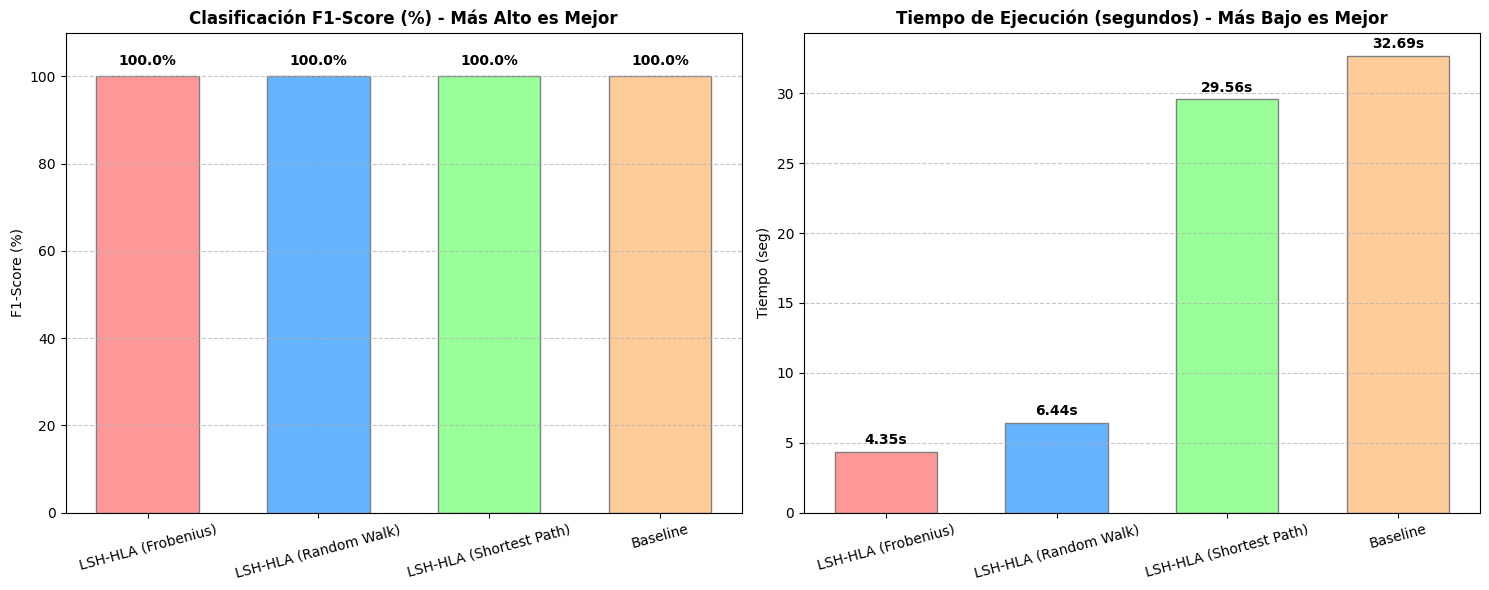

In [8]:
# 1. Crear DataFrame para resumir resultados
df_perf = pd.DataFrame({
    "Configuración": ["LSH-HLA (Frobenius)", "LSH-HLA (Random Walk)", "LSH-HLA (Shortest Path)", "Baseline"],
    "F1-score": [
        f1_results["Frobenius"] * 100, 
        f1_results["Random Walk"] * 100, 
        f1_results["Shortest Path"] * 100, 
        f1_results["Baseline"] * 100
    ],
    "Tiempo (seg)": [
        time_results["Frobenius"],
        time_results["Random Walk"],
        time_results["Shortest Path"],
        time_results["Baseline"]
    ]
})

print("=== TABLA DE RENDIMIENTO ===")
print(df_perf.to_string(index=False))

# 2. Graficar barra comparativa de F1-score y Tiempo
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
colors = ['#ff9999','#66b3ff','#99ff99','#ffcc99']

# Subplot 1: F1-score
bars1 = ax1.bar(df_perf["Configuración"], df_perf["F1-score"], color=colors, edgecolor='gray', width=0.6)
ax1.set_title("Clasificación F1-Score (%) - Más Alto es Mejor", fontsize=12, fontweight='bold')
ax1.set_ylabel("F1-Score (%)")
ax1.set_ylim(0, 110)
ax1.grid(axis='y', linestyle='--', alpha=0.7)
ax1.set_xticklabels(df_perf["Configuración"], rotation=15)
for bar in bars1:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2.0, yval + 2, f"{yval:.1f}%", ha='center', va='bottom', fontweight='bold')

# Subplot 2: Tiempos de ejecución
bars2 = ax2.bar(df_perf["Configuración"], df_perf["Tiempo (seg)"], color=colors, edgecolor='gray', width=0.6)
ax2.set_title("Tiempo de Ejecución (segundos) - Más Bajo es Mejor", fontsize=12, fontweight='bold')
ax2.set_ylabel("Tiempo (seg)")
ax2.grid(axis='y', linestyle='--', alpha=0.7)
ax2.set_xticklabels(df_perf["Configuración"], rotation=15)
for bar in bars2:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2.0, yval + max(df_perf["Tiempo (seg)"])*0.01, f"{yval:.2f}s", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()


In [9]:
df_perf

,Configuración,F1-score,Tiempo (seg)
0,LSH-HLA (Frobenius),100.0,4.353797
1,LSH-HLA (Random Walk),100.0,6.438708
2,LSH-HLA (Shortest Path),100.0,29.560030
3,Baseline,100.0,32.685160
